# CVRP Food Delivery: Extension, Third Method and Scalability Study

### Contributions in this notebook

| # | Contribution | Why it matters |
|---|---|---|
| 1 | **Reproducible instance generation** (`hashlib`-based coordinates, fixed seeds) | The original used Python's built-in `hash()`, which is salted per process, so every rerun produced a different map and different results. |
| 2 | **Correct optimality reporting for the ILP** (solver solution status + CBC lower bound + MIP gap) | PuLP labels a run that stopped on the time limit as `"Optimal"`. The original 15-node result (300.07 s on a 300 s limit) was therefore not proven optimal. |
| 3 | **Strengthened ILP** with a valid fleet-size lower-bound cut | Tightens the LP relaxation so CBC proves optimality faster on small instances. |
| 4 | **Third method: Clarke-Wright Savings + Simulated Annealing** (relocate / swap / 2-opt moves) | A constructive heuristic plus a trajectory metaheuristic, contrasted with the population-based GA. |
| 5 | **GA elitism finding** | `eaSimple` keeps the Hall of Fame outside the population, so the claimed elitism does not happen (documented, with evidence in the convergence plot). |
| 6 | **Scalability study**: n = 8 to 100 customers, 10 random seeds per stochastic method, lower-bound based gaps, statistical test | Turns a two-point comparison into evidence on quality, runtime, scalability and robustness. |

## 1. Setup and configuration

In [3]:
import hashlib, math, os, random, re, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import pulp
from deap import base, creator, tools, algorithms
from scipy.stats import mannwhitneyu

warnings.filterwarnings("ignore")
matplotlib.rcParams["figure.dpi"] = 110

# ---------------- Experiment configuration ----------------
SIZES          = [8, 10, 12, 15, 20, 30, 50, 100]   # number of customers n
ILP_MAX_N      = 30        # largest n given to the exact ILP
ILP_TIME_LIMIT = 300       # seconds (same budget as the original notebook)
SEEDS          = list(range(10))   # independent runs for GA and SA
CAPACITY       = 120       # vehicle (rider box) capacity in demand units, fixed for all n
GA_POP, GA_GEN = 200, 500  # same GA settings as the original notebook
OUT_DIR        = Path("results"); OUT_DIR.mkdir(exist_ok=True)

print("PuLP", pulp.__version__, "| sizes:", SIZES, "| seeds:", len(SEEDS))

PuLP 2.8.0 | sizes: [8, 10, 12, 15, 20, 30, 50, 100] | seeds: 10


## 2. Reproducible instance generation)

The data staging follows Member 1's logic exactly (busiest active restaurant as depot, non-cancelled orders, one node per unique customer, demand = `round(total_amount / 100)`).

The only change is how mock coordinates are produced. The addresses in the dataset are synthetic, so live geocoding fails and coordinates are generated around central Chennai. The original seeded this with `hash(location_str)`. Since Python 3.3, string hashing is randomised per interpreter process (`PYTHONHASHSEED`), so the coordinates, the distance matrix, and every result changed between runs. Here the seed comes from an MD5 digest of the address, which is identical on every machine and every run.

In [4]:
CHENNAI_CENTER = (13.0827, 80.2707)

def stable_coords(location_str, center=CHENNAI_CENTER, spread=0.08):
    # Deterministic pseudo-geocode: same address -> same point, on every run and machine.
    seed = int.from_bytes(hashlib.md5(location_str.encode("utf-8")).digest()[:4], "little")
    rng = np.random.RandomState(seed)
    return (round(center[0] + rng.uniform(-spread, spread), 6),
            round(center[1] + rng.uniform(-spread, spread), 6))

restaurants = pd.read_csv("restaurants.csv")
customers   = pd.read_csv("customers.csv")
orders      = pd.read_csv("orders.csv")

active = restaurants[restaurants["is_active"] == 1]
valid_orders = orders[(orders["status"] != "Cancelled") &
                      (orders["restaurant_id"].isin(active["restaurant_id"]))]
DEPOT_ID   = valid_orders["restaurant_id"].value_counts().index[0]
depot_info = restaurants.loc[restaurants["restaurant_id"] == DEPOT_ID].iloc[0]
depot_xy   = stable_coords(depot_info["location"])

nodes = (valid_orders.merge(customers[["customer_id", "name", "location"]], on="customer_id", how="left")
                     .drop_duplicates(subset="customer_id").reset_index(drop=True))
nodes["demand"] = (nodes["total_amount"] / 100).round().astype(int).clip(lower=1)
xy = nodes["location"].apply(stable_coords)
nodes["lat"], nodes["lon"] = xy.str[0], xy.str[1]

print(f"Depot: {depot_info['name']} (id {DEPOT_ID}) at {depot_xy}")
print(f"Unique customer nodes available: {len(nodes)}")
print(f"Demand per customer: mean {nodes['demand'].mean():.1f}, min {nodes['demand'].min()}, max {nodes['demand'].max()}")
nodes[["customer_id", "name", "lat", "lon", "demand"]].head()

Depot: Classic Cafe (Desserts) (id 106) at (13.142509, 80.278896)
Unique customer nodes available: 337
Demand per customer: mean 24.8, min 1, max 50


,customer_id,name,lat,lon,demand
0,114,Hredhaan Vyas,13.102728,80.327212,31
1,235,Ekaja Chand,13.036469,80.348363,12
2,192,Robert Lad,13.007624,80.334751,9
3,472,Adweta More,13.140018,80.335593,44
4,271,Yauvani Bora,13.101490,80.330432,7


In [5]:
def haversine_matrix(points):
    # Vectorised great-circle distance matrix in km (node 0 = depot).
    p = np.radians(np.asarray(points))
    lat, lon = p[:, 0][:, None], p[:, 1][:, None]
    a = (np.sin((lat.T - lat) / 2) ** 2 +
         np.cos(lat) * np.cos(lat.T) * np.sin((lon.T - lon) / 2) ** 2)
    return np.round(2 * 6371 * np.arcsin(np.sqrt(a)), 3)

def make_instance(n, capacity=CAPACITY):
    sub = nodes.head(n)
    pts = [depot_xy] + list(zip(sub["lat"], sub["lon"]))
    dem = [0] + sub["demand"].tolist()            # dem[0] = depot
    return {"n": n, "Q": capacity, "dist": haversine_matrix(pts),
            "dem": dem, "pts": pts, "names": ["DEPOT"] + sub["name"].tolist()}

INSTANCES = {n: make_instance(n) for n in SIZES}
pd.DataFrame([{"n": n, "total_demand": sum(I["dem"]),
               "min_vehicles": math.ceil(sum(I["dem"]) / I["Q"])}
              for n, I in INSTANCES.items()])

,n,total_demand,min_vehicles
0,8,208,2
1,10,254,3
2,12,297,3
3,15,358,3
4,20,480,4
5,30,715,6
6,50,1282,11
7,100,2495,21


### Shared utilities: route cost and an independent feasibility checker

Every solution from every method is passed through `check_solution`, which verifies that each customer is visited exactly once, every route starts and ends at the depot, and no route exceeds capacity.

In [6]:
def route_cost(route, D):
    # route = [c1, c2, ...] without depot
    if not route:
        return 0.0
    c = D[0, route[0]] + D[route[-1], 0]
    for a, b in zip(route[:-1], route[1:]):
        c += D[a, b]
    return c

def solution_cost(routes, D):
    return sum(route_cost(r, D) for r in routes)

def check_solution(routes, I):
    seen = sorted(c for r in routes for c in r)
    assert seen == list(range(1, I["n"] + 1)), "each customer must be visited exactly once"
    for r in routes:
        assert sum(I["dem"][c] for c in r) <= I["Q"], "capacity violated"
    return True

## 3. Exact method revisited: MTZ ILP with honest optimality reporting 

The formulation is Member 1's two-index MTZ model:

$$\min \sum_{i \ne j} c_{ij} x_{ij}$$
subject to in/out degree 1 for every customer, depot flow balance, at most $K$ vehicles, and $u_i - u_j + Q x_{ij} \le Q - d_j$, $d_i \le u_i \le Q$.

**Added valid inequality (fleet lower bound).** Every route carries at most $Q$, so at least $\lceil \sum_i d_i / Q \rceil$ vehicles must leave the depot:

$$\sum_{j \in V'} x_{0j} \;\ge\; \left\lceil \frac{\sum_{i \in V'} d_i}{Q} \right\rceil$$

This never removes a feasible solution but cuts off fractional LP solutions that use "too few" vehicles, which tightens the bound CBC works with.

**Honest status.** `pulp.LpStatus[model.status]` returns `"Optimal"` even when CBC stops on the time limit with only a feasible incumbent. The correct field is `model.sol_status` (`1` = proven optimal, `2` = feasible only). We also parse CBC's log for the best **lower bound**, which gives a certified gap for every instance, including the ones the heuristics solve.

In [7]:
def solve_ilp(I, time_limit=ILP_TIME_LIMIT, fleet_cut=True, log_name=None):
    n, Q, D, dem = I["n"], I["Q"], I["dist"], I["dem"]
    V, Vp = range(n + 1), range(1, n + 1)
    K_min = math.ceil(sum(dem) / Q)
    K = K_min + 1                                   # same fleet size rule 

    m = pulp.LpProblem("CVRP_MTZ", pulp.LpMinimize)
    x = {(i, j): pulp.LpVariable(f"x_{i}_{j}", cat="Binary") for i in V for j in V if i != j}
    u = {i: pulp.LpVariable(f"u_{i}", lowBound=dem[i], upBound=Q) for i in Vp}
    m += pulp.lpSum(D[i, j] * x[i, j] for (i, j) in x)
    for j in Vp:
        m += pulp.lpSum(x[i, j] for i in V if i != j) == 1
        m += pulp.lpSum(x[j, k] for k in V if k != j) == 1
    out0 = pulp.lpSum(x[0, j] for j in Vp)
    m += out0 <= K
    m += out0 == pulp.lpSum(x[i, 0] for i in Vp)
    if fleet_cut:
        m += out0 >= K_min
    for i in Vp:
        for j in Vp:
            if i != j:
                m += u[i] - u[j] + Q * x[i, j] <= Q - dem[j]

    log_path = str(OUT_DIR / (log_name or f"cbc_n{n}.log"))
    t0 = time.time()
    m.solve(pulp.PULP_CBC_CMD(msg=False, timeLimit=time_limit, logPath=log_path))
    elapsed = time.time() - t0

    proven = (m.sol_status == pulp.LpSolutionOptimal)
    has_sol = m.sol_status in (pulp.LpSolutionOptimal, pulp.LpSolutionIntegerFeasible)
    obj = pulp.value(m.objective) if has_sol else float("nan")

    # Best bound from the CBC log (only printed when the search is stopped early)
    lb = obj if proven else float("nan")
    log = Path(log_path).read_text(errors="ignore") if Path(log_path).exists() else ""
    hits = re.findall(r"Lower bound:\s+([-\d.eE+]+)", log)
    if hits and not proven:
        lb = float(hits[-1])
    if not hits and not proven:   # fall back to the last "best possible" in the progress lines
        bp = re.findall(r"best possible\s+([-\d.eE+]+)", log)
        if bp:
            lb = float(bp[-1])

    routes = []
    if has_sol:
        succ = {i: j for (i, j), v in x.items() if v.varValue and v.varValue > 0.5}
        for j in Vp:
            if x[0, j].varValue and x[0, j].varValue > 0.5:
                r, cur = [], j
                while cur != 0:
                    r.append(cur); cur = succ[cur]
                routes.append(r)
        check_solution(routes, I)

    return {"method": "ILP (MTZ + fleet cut)" if fleet_cut else "ILP (MTZ)",
            "n": n, "seed": None, "distance": obj, "time_s": elapsed,
            "vehicles": len(routes) if routes else np.nan,
            "status": "Optimal (proven)" if proven else ("Feasible, time limit" if has_sol else "No solution"),
            "lower_bound": lb, "routes": routes}

### 3.1 Re-checking the original 15-customer claim

We solve the 15-customer instance twice: with Member 1's original model, and with the fleet cut. Both use the same 300 s limit. This directly tests whether the original "Optimal" label was justified.

In [8]:
I15 = INSTANCES[15]
ilp15_orig = solve_ilp(I15, fleet_cut=False, log_name="cbc_n15_original.log")
ilp15_cut  = solve_ilp(I15, fleet_cut=True,  log_name="cbc_n15_cut.log")

recheck = pd.DataFrame([{k: r[k] for k in ["method", "distance", "lower_bound", "time_s", "vehicles", "status"]}
                        for r in (ilp15_orig, ilp15_cut)])
recheck["gap_%"] = 100 * (recheck["distance"] - recheck["lower_bound"]) / recheck["distance"]
recheck.round(3)

,method,distance,lower_bound,time_s,vehicles,status,gap_%
0,ILP (MTZ),106.466,76.524,300.179,4,"Feasible, time limit",28.124
1,ILP (MTZ + fleet cut),104.225,104.225,175.975,4,Optimal (proven),0.000


## 4. Genetic Algorithm baseline (Member 1's design, seeding fixed)

Same chromosome (giant tour permutation), greedy capacity split, tournament selection (3), ordered crossover, shuffle-index mutation, elitism via Hall of Fame, population 200, 500 generations.

**Fix:** the original called `random.seed(42)` *after* creating the initial population, so the starting population (and therefore the result) was not reproducible. Here the seed is set before anything random happens, and the GA is run with 10 different seeds per instance.

**Observation (not changed, so the baseline stays faithful):** the original design table says "Elitism: best individual always survives (Hall of Fame)". In DEAP, `algorithms.eaSimple` only *records* the best individual in the Hall of Fame. It does not put it back into the population, and the whole population is replaced by offspring every generation. So the GA has no real elitism: the best tour in the population can be lost, which is visible as the non-monotone faint curve in the convergence plot (Section 7). The returned solution is still the Hall of Fame best, so results are valid, but search effort is wasted re-discovering lost solutions. A `(mu + lambda)` scheme (`eaMuPlusLambda`) or explicit elite re-insertion would fix this.

In [9]:
def ga_decode(perm, dem, Q):
    routes, cur, load = [], [], 0
    for c in perm:
        if load + dem[c] > Q:
            routes.append(cur); cur, load = [], 0
        cur.append(c); load += dem[c]
    if cur:
        routes.append(cur)
    return routes

if "FitnessMin" not in creator.__dict__:
    creator.create("FitnessMin", base.Fitness, weights=(-1.0,))
if "Individual" not in creator.__dict__:
    creator.create("Individual", list, fitness=creator.FitnessMin)

def run_ga(I, seed, pop_size=GA_POP, n_gen=GA_GEN, cxpb=0.8, mutpb=0.2):
    random.seed(seed); np.random.seed(seed)            # seed BEFORE population creation
    n, D, dem, Q = I["n"], I["dist"], I["dem"], I["Q"]
    tb = base.Toolbox()
    # cxOrdered works on 0..n-1 indices, so genes are indices and gene g = customer g+1
    tb.register("indices", random.sample, range(n), n)
    tb.register("individual", tools.initIterate, creator.Individual, tb.indices)
    tb.register("population", tools.initRepeat, list, tb.individual)
    tb.register("evaluate", lambda ind: (solution_cost(ga_decode([g + 1 for g in ind], dem, Q), D),))
    tb.register("select", tools.selTournament, tournsize=3)
    tb.register("mate", tools.cxOrdered)
    tb.register("mutate", tools.mutShuffleIndexes, indpb=0.05)

    stats = tools.Statistics(lambda ind: ind.fitness.values[0]); stats.register("min", np.min)
    hof = tools.HallOfFame(1)
    t0 = time.time()
    pop = tb.population(n=pop_size)
    pop, log = algorithms.eaSimple(pop, tb, cxpb=cxpb, mutpb=mutpb, ngen=n_gen,
                                   stats=stats, halloffame=hof, verbose=False)
    elapsed = time.time() - t0
    routes = ga_decode([g + 1 for g in hof[0]], dem, Q)
    check_solution(routes, I)
    return {"method": "GA (Member 1)", "n": n, "seed": seed, "distance": solution_cost(routes, D),
            "time_s": elapsed, "vehicles": len(routes), "status": "Feasible",
            "routes": routes, "curve": log.select("min")}

## 5. Third method: Clarke-Wright Savings + Simulated Annealing (contribution #4)

### 5.1 Clarke-Wright Savings (constructive heuristic)

Start with one route per customer, $0 \to i \to 0$. Merging the routes ending at $i$ and starting at $j$ saves

$$s_{ij} = c_{0i} + c_{0j} - c_{ij}.$$

All savings are sorted in decreasing order and merges are applied greedily whenever $i$ and $j$ are endpoints of two different routes and the merged load fits within $Q$. It is deterministic, runs in $O(n^2 \log n)$, and is the classical industrial baseline for VRP.

### 5.2 Simulated Annealing (trajectory metaheuristic)

SA starts from the Clarke-Wright solution and repeatedly applies one random move:

| Move | Description | Capacity check |
|---|---|---|
| **Relocate** | move customer $c$ next to one of its nearest neighbours $c'$ (same or another route) | target route load |
| **Swap** | exchange $c$ and a nearby $c'$ that sit on different routes | both route loads |
| **2-opt\*** | cut two routes after $c$ and $c'$ and exchange their tails (two variants) | both new route loads |
| **2-opt** | reverse a segment inside one route (removes crossings) | not needed |

**Granular neighbourhood.** Moves only pair a customer with one of its 10 nearest customers. With capacity this tight (most Clarke-Wright vehicles leave 115 to 120 of 120 units loaded), purely random pairs are almost always infeasible or pointless; restricting to nearby pairs is the standard remedy (Toth and Vigo, 2003).

A worse neighbour with cost increase $\Delta$ is accepted with probability $e^{-\Delta/T}$. The start temperature $T_0$ is calibrated so that an average uphill move is initially accepted with probability 0.3 (lower than usual, because SA starts from a good Clarke-Wright solution rather than a random one). $T$ decreases geometrically to $10^{-3} T_0$ over $\max(100000, 5000n)$ iterations. Only the routes touched by a move are re-costed, so each iteration is $O(\text{route length})$, not $O(n)$.

**Why SA alongside the GA?** The GA keeps a population and recombines whole giant tours. Its split decoder can only cut the permutation in order, so it often leaves part-filled vehicles. SA works directly on routes and makes many cheap, local, capacity-aware changes. Comparing them shows population-based versus trajectory-based search on the same model.

In [10]:
def clarke_wright(I):
    n, D, dem, Q = I["n"], I["dist"], I["dem"], I["Q"]
    route_of = {i: i for i in range(1, n + 1)}            # customer -> route id
    routes   = {i: [i] for i in range(1, n + 1)}
    load     = {i: dem[i] for i in range(1, n + 1)}
    savings = sorted(((D[0, i] + D[0, j] - D[i, j], i, j)
                      for i in range(1, n + 1) for j in range(i + 1, n + 1)), reverse=True)
    for s, i, j in savings:
        if s <= 0:
            break
        ri, rj = route_of[i], route_of[j]
        if ri == rj or load[ri] + load[rj] > Q:
            continue
        A, B = routes[ri], routes[rj]
        # i and j must be route endpoints; orient so A ends with i and B starts with j
        if A[-1] != i:
            if A[0] == i: A = A[::-1]
            else: continue
        if B[0] != j:
            if B[-1] == j: B = B[::-1]
            else: continue
        merged = A + B
        routes[ri], load[ri] = merged, load[ri] + load[rj]
        for c in B:
            route_of[c] = ri
        del routes[rj], load[rj]
    return list(routes.values())


def simulated_annealing(I, init_routes, seed, iters=None, p_accept0=0.3, t_end_ratio=1e-3, k_near=10):
    rng = random.Random(seed)
    n, D, dem, Q = I["n"], I["dist"], I["dem"], I["Q"]
    iters = iters or max(100000, 5000 * n)
    R    = [list(r) for r in init_routes]
    cost = [route_cost(r, D) for r in R]
    load = [sum(dem[c] for c in r) for r in R]
    where = {c: k for k, r in enumerate(R) for c in r}       # customer -> route index
    total = sum(cost)
    # granular neighbourhood: each customer only interacts with its k nearest customers
    K = min(k_near, n - 1)
    near = {c: [int(j) for j in np.argsort(D[c, 1:]) + 1 if j != c][:K] for c in range(1, n + 1)}

    def cost_of(*rs):
        return sum(route_cost(r, D) for r in rs)

    def propose():
        # returns (delta, {route_index: new_route}) or None if the move is infeasible
        c  = rng.randint(1, n); c2 = rng.choice(near[c])
        a, b = where[c], where[c2]
        mv = rng.random()
        if mv < 0.35:                                   # RELOCATE c next to c2
            ra = R[a][:]; ra.remove(c)
            if a == b:
                pos = ra.index(c2) + rng.randint(0, 1)
                nb = ra[:pos] + [c] + ra[pos:]
                return cost_of(nb) - cost[a], {a: nb}
            if load[b] + dem[c] > Q: return None
            pos = R[b].index(c2) + rng.randint(0, 1)
            nb = R[b][:pos] + [c] + R[b][pos:]
            return cost_of(ra, nb) - cost[a] - cost[b], {a: ra, b: nb}
        if mv < 0.55:                                   # SWAP c and c2 (different routes)
            if a == b: return None
            if load[a] - dem[c] + dem[c2] > Q or load[b] - dem[c2] + dem[c] > Q: return None
            na = [c2 if x == c else x for x in R[a]]
            nb = [c if x == c2 else x for x in R[b]]
            return cost_of(na, nb) - cost[a] - cost[b], {a: na, b: nb}
        if mv < 0.80:                                   # 2-OPT* (exchange route tails)
            if a == b: return None
            i, j = R[a].index(c), R[b].index(c2)
            A1, A2, B1, B2 = R[a][:i + 1], R[a][i + 1:], R[b][:j + 1], R[b][j + 1:]
            if rng.random() < 0.5:
                na, nb = A1 + B2, B1 + A2               # c -> next(c2),  c2 -> next(c)
            else:
                na, nb = A1 + B1[::-1], A2[::-1] + B2   # c -> c2,  next(c) -> next(c2)
            if sum(dem[x] for x in na) > Q or sum(dem[x] for x in nb) > Q: return None
            return cost_of(na, nb) - cost[a] - cost[b], {a: na, b: nb}
        # 2-OPT inside one route (reverse a segment)
        if len(R[a]) < 3: return None
        i, j = sorted(rng.sample(range(len(R[a])), 2))
        na = R[a][:i] + R[a][i:j + 1][::-1] + R[a][j + 1:]
        return cost_of(na) - cost[a], {a: na}

    # Calibrate T0 so an average uphill move is accepted with probability p_accept0
    ups = []
    for _ in range(20000):
        p = propose()
        if p and p[0] > 1e-9: ups.append(p[0])
        if len(ups) >= 300: break
    T0 = (-np.mean(ups) / math.log(p_accept0)) if ups else 1e-3 * total / n
    alpha = t_end_ratio ** (1.0 / iters)

    best, best_routes, curve = total, [r[:] for r in R if r], []
    T, t0 = T0, time.time()
    for it in range(iters):
        p = propose()
        if p is not None:
            delta, changes = p
            if delta < 0 or rng.random() < math.exp(-delta / T):
                for k, r in changes.items():
                    R[k] = r; cost[k] = route_cost(r, D); load[k] = sum(dem[x] for x in r)
                    for x in r: where[x] = k
                total += delta
                if total < best - 1e-9:
                    best, best_routes = total, [r[:] for r in R if r]
        T *= alpha
        if it % 500 == 0:
            curve.append(best)
    return best_routes, time.time() - t0, curve


def run_cw(I):
    t0 = time.time()
    routes = clarke_wright(I)
    elapsed = time.time() - t0
    check_solution(routes, I)
    return {"method": "Clarke-Wright", "n": I["n"], "seed": None,
            "distance": solution_cost(routes, I["dist"]), "time_s": elapsed,
            "vehicles": len(routes), "status": "Feasible", "routes": routes}

def run_cw_sa(I, seed):
    t0 = time.time()
    init = clarke_wright(I)
    routes, _, curve = simulated_annealing(I, init, seed)
    elapsed = time.time() - t0
    check_solution(routes, I)
    return {"method": "CW + SA (Member 2)", "n": I["n"], "seed": seed,
            "distance": solution_cost(routes, I["dist"]), "time_s": elapsed,
            "vehicles": len(routes), "status": "Feasible", "routes": routes, "curve": curve}

### 5.3 Quick sanity run on the 15-customer instance

In [11]:
cw15 = run_cw(I15)
sa15 = run_cw_sa(I15, seed=0)
ga15 = run_ga(I15, seed=0)
for r in (ilp15_cut, cw15, sa15, ga15):
    print(f"{r['method']:<24} {r['distance']:8.2f} km  {r['time_s']:7.2f} s  vehicles={r['vehicles']}")
print()
for k, route in enumerate(sa15["routes"], 1):
    print(f"CW+SA route {k}: " + " -> ".join(I15["names"][c] for c in [0] + route + [0]),
          f"| load {sum(I15['dem'][c] for c in route)}/{I15['Q']}")

ILP (MTZ + fleet cut)      104.22 km   175.97 s  vehicles=4
Clarke-Wright              108.05 km     0.00 s  vehicles=4
CW + SA (Member 2)         104.22 km     0.31 s  vehicles=4
GA (Member 1)              110.09 km     2.04 s  vehicles=4

CW+SA route 1: DEPOT -> Barkha Sethi -> Logan Randhawa -> Ekani Krish -> Chaaya Bhatti -> Thomas Grover -> DEPOT | load 113/120
CW+SA route 2: DEPOT -> Urvashi Mittal -> Ladli Dugar -> Robert Lad -> Ekaja Chand -> Yauvani Bora -> Hredhaan Vyas -> DEPOT | load 100/120
CW+SA route 3: DEPOT -> Meera Sidhu -> Samuel Subramaniam -> DEPOT | load 94/120
CW+SA route 4: DEPOT -> Adweta More -> Nilima Patil -> DEPOT | load 51/120


## 6. Scalability study (contribution #5)

For every instance size $n \in \{8,10,12,15,20,30,50,100\}$ we run:

* **ILP** (MTZ + fleet cut, 300 s limit) for $n \le 30$; beyond that the model has more than 2,500 binary variables and CBC cannot close the gap.
* **Clarke-Wright** (deterministic, one run).
* **GA** and **CW + SA**, each with **10 independent seeds**.

Quality is measured two ways:

* **Gap to best known**: relative to the best distance found by any method on that instance.
* **Gap to lower bound**: relative to the ILP's proven lower bound. This is a *certified* worst-case gap, because no solution can be cheaper than the bound.

In [12]:
records, curves = [], {}
ilp_results = {15: ilp15_cut}
for n in SIZES:
    I = INSTANCES[n]
    t_n = time.time()
    if n <= ILP_MAX_N and n not in ilp_results:
        ilp_results[n] = solve_ilp(I)
    if n in ilp_results:
        records.append(ilp_results[n])
    records.append(run_cw(I))
    for s in SEEDS:
        g = run_ga(I, s);    records.append(g)
        a = run_cw_sa(I, s); records.append(a)
        if s == 0:
            curves[n] = {"GA": g["curve"], "SA": a["curve"]}
    print(f"n={n:>3} done in {time.time() - t_n:6.1f} s")

res = pd.DataFrame([{k: v for k, v in r.items() if k not in ("routes", "curve")} for r in records])
res.to_csv(OUT_DIR / "all_runs.csv", index=False)
res.head()

n=  8 done in   19.4 s
n= 10 done in   22.0 s
n= 12 done in   25.3 s
n= 15 done in   23.3 s
n= 20 done in  327.4 s
n= 30 done in  334.5 s
n= 50 done in   51.9 s
n=100 done in   93.9 s


,method,n,seed,distance,time_s,vehicles,status,lower_bound
0,ILP (MTZ + fleet cut),8,NaN,73.735,0.580280,2,Optimal (proven),73.735
1,Clarke-Wright,8,NaN,73.735,0.000035,2,Feasible,NaN
2,GA (Member 1),8,0.0,73.735,1.585418,2,Feasible,NaN
3,CW + SA (Member 2),8,0.0,73.735,0.347220,2,Feasible,NaN
4,GA (Member 1),8,1.0,76.371,1.605150,2,Feasible,NaN


In [13]:
best_known = res.groupby("n")["distance"].min()
lower_bound = res[res["method"].str.startswith("ILP")].set_index("n")["lower_bound"]

summary = (res.groupby(["n", "method"])
              .agg(best=("distance", "min"), mean=("distance", "mean"), std=("distance", "std"),
                   time_mean_s=("time_s", "mean"), vehicles=("vehicles", "median"))
              .reset_index())
summary["gap_best_known_%"] = 100 * (summary["mean"] - summary["n"].map(best_known)) / summary["n"].map(best_known)
summary["gap_lower_bound_%"] = 100 * (summary["mean"] - summary["n"].map(lower_bound)) / summary["mean"]
summary["std"] = summary["std"].fillna(0)
summary.to_csv(OUT_DIR / "summary.csv", index=False)

ilp_table = res[res["method"].str.startswith("ILP")][["n", "distance", "lower_bound", "time_s", "status"]].copy()
ilp_table["mip_gap_%"] = 100 * (ilp_table["distance"] - ilp_table["lower_bound"]) / ilp_table["distance"]
print("Exact method status by size")
display(ilp_table.round(2))
print("\nAll methods (mean over seeds for GA and CW+SA)")
display(summary.round(2))

Exact method status by size


,n,distance,lower_bound,time_s,status,mip_gap_%
0,8,73.74,73.74,0.58,Optimal (proven),0.00
22,10,86.75,86.75,0.98,Optimal (proven),0.00
44,12,92.59,92.59,3.13,Optimal (proven),0.00
66,15,104.22,104.22,175.97,Optimal (proven),0.00
88,20,128.24,90.45,300.14,"Feasible, time limit",29.46
110,30,214.37,102.14,299.33,"Feasible, time limit",52.36



All methods (mean over seeds for GA and CW+SA)


,n,method,best,mean,std,time_mean_s,vehicles,gap_best_known_%,gap_lower_bound_%
0,8,CW + SA (Member 2),73.74,73.74,0.00,0.30,2.0,0.00,0.00
1,8,Clarke-Wright,73.74,73.74,0.00,0.00,2.0,0.00,0.00
2,8,GA (Member 1),73.74,74.32,1.10,1.58,2.0,0.79,0.79
3,8,ILP (MTZ + fleet cut),73.74,73.74,0.00,0.58,2.0,0.00,0.00
4,10,CW + SA (Member 2),86.75,86.75,0.00,0.33,3.0,0.00,0.00
5,10,Clarke-Wright,91.11,91.11,0.00,0.00,3.0,5.02,4.78
6,10,GA (Member 1),86.75,87.08,0.47,1.77,3.0,0.37,0.37
7,10,ILP (MTZ + fleet cut),86.75,86.75,0.00,0.98,3.0,0.00,0.00
8,12,CW + SA (Member 2),92.59,92.59,0.00,0.34,3.0,0.00,0.00
9,12,Clarke-Wright,93.27,93.27,0.00,0.00,3.0,0.73,0.72


### 6.1 Statistical comparison: GA vs CW + SA

A two-sided Mann-Whitney U test on the 10 final distances per method, for each $n$. It is non-parametric, so it does not assume normally distributed results.

In [14]:
rows = []
for n in SIZES:
    ga = res[(res.n == n) & (res.method == "GA (Member 1)")]["distance"]
    sa = res[(res.n == n) & (res.method == "CW + SA (Member 2)")]["distance"]
    if np.allclose(ga.values, sa.values[0]) and np.allclose(sa.values, sa.values[0]):
        p = 1.0
    else:
        p = mannwhitneyu(ga, sa, alternative="two-sided").pvalue
    rows.append({"n": n, "GA mean": ga.mean(), "SA mean": sa.mean(),
                 "SA better by %": 100 * (ga.mean() - sa.mean()) / ga.mean(),
                 "p-value": p, "significant (p<0.05)": p < 0.05})
stat = pd.DataFrame(rows); stat.to_csv(OUT_DIR / "ga_vs_sa_test.csv", index=False)
stat.round(4)

,n,GA mean,SA mean,SA better by %,p-value,significant (p<0.05)
0,8,74.3209,73.7350,0.7883,0.0776,False
1,10,87.0751,86.7540,0.3688,0.9376,False
2,12,93.2480,92.5940,0.7014,0.0111,True
3,15,108.8464,106.0226,2.5943,0.0086,True
4,20,127.9955,118.2220,7.6358,0.0001,True
5,30,175.3369,168.6154,3.8335,0.0109,True
6,50,345.7002,270.0000,21.8976,0.0002,True
7,100,798.6005,506.5968,36.5644,0.0002,True


## 7. Visual results

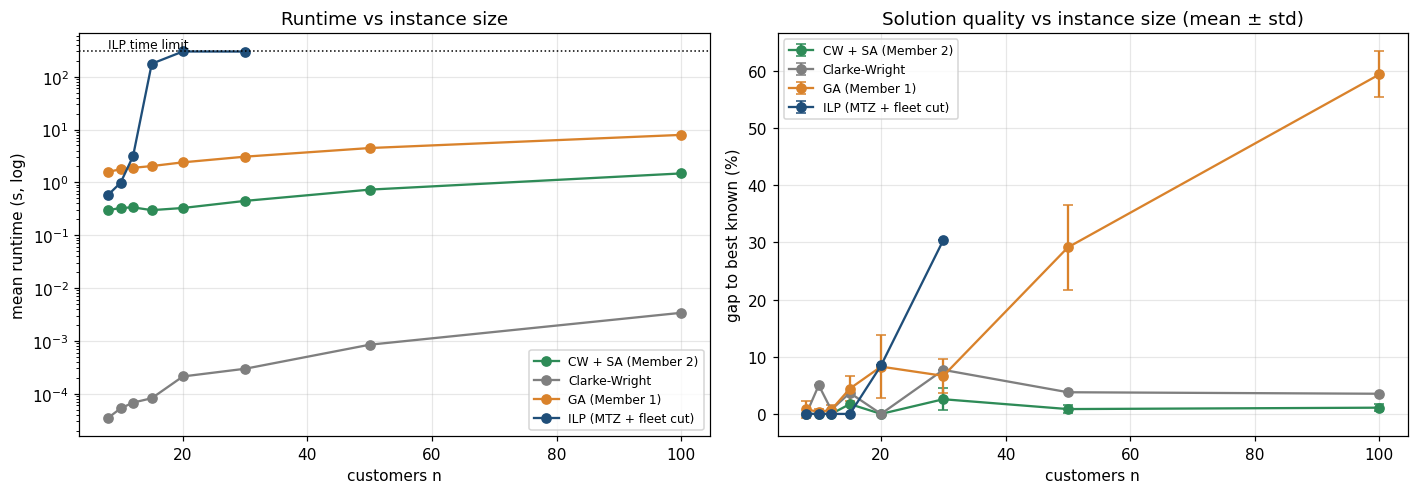

In [15]:
COL = {"ILP (MTZ + fleet cut)": "#1f4e79", "Clarke-Wright": "#7f7f7f",
       "GA (Member 1)": "#d9822b", "CW + SA (Member 2)": "#2e8b57"}

fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
for m, g in summary.groupby("method"):
    ax[0].plot(g["n"], g["time_mean_s"], "o-", color=COL[m], label=m)
    ax[1].errorbar(g["n"], g["gap_best_known_%"],
                   yerr=100 * g["std"] / g["n"].map(best_known), fmt="o-",
                   color=COL[m], capsize=3, label=m)
ax[0].set_yscale("log"); ax[0].set_xlabel("customers n"); ax[0].set_ylabel("mean runtime (s, log)")
ax[0].set_title("Runtime vs instance size"); ax[0].axhline(ILP_TIME_LIMIT, ls=":", c="k", lw=1)
ax[0].text(SIZES[0], ILP_TIME_LIMIT * 1.15, "ILP time limit", fontsize=8)
ax[1].set_xlabel("customers n"); ax[1].set_ylabel("gap to best known (%)")
ax[1].set_title("Solution quality vs instance size (mean ± std)")
for a in ax: a.grid(alpha=.3); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT_DIR / "scalability.png", dpi=150); plt.show()

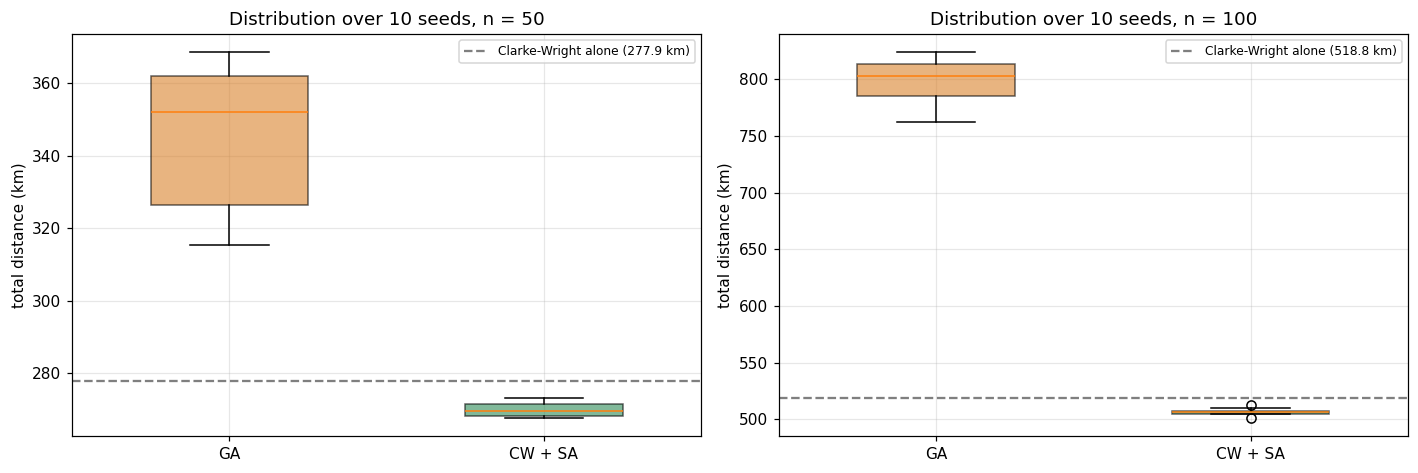

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
for k, n in enumerate([50, 100]):
    data = [res[(res.n == n) & (res.method == m)]["distance"] for m in ["GA (Member 1)", "CW + SA (Member 2)"]]
    bp = ax[k].boxplot(data, patch_artist=True, widths=.5)
    ax[k].set_xticks([1, 2]); ax[k].set_xticklabels(["GA", "CW + SA"])
    for patch, c in zip(bp["boxes"], [COL["GA (Member 1)"], COL["CW + SA (Member 2)"]]):
        patch.set_facecolor(c); patch.set_alpha(.6)
    cw = res[(res.n == n) & (res.method == "Clarke-Wright")]["distance"].iloc[0]
    ax[k].axhline(cw, ls="--", c=COL["Clarke-Wright"], label=f"Clarke-Wright alone ({cw:.1f} km)")
    ax[k].set_title(f"Distribution over 10 seeds, n = {n}"); ax[k].set_ylabel("total distance (km)")
    ax[k].legend(fontsize=8); ax[k].grid(alpha=.3)
plt.tight_layout(); plt.savefig(OUT_DIR / "robustness_boxplots.png", dpi=150); plt.show()

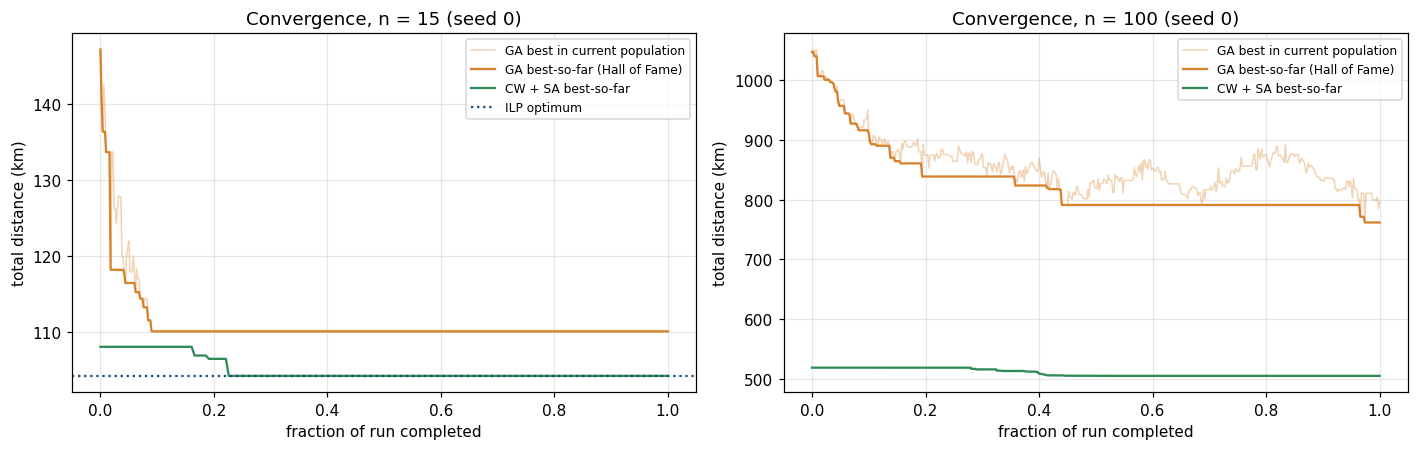

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for k, n in enumerate([15, 100]):
    ga_c, sa_c = curves[n]["GA"], curves[n]["SA"]
    x_ga = np.linspace(0, 1, len(ga_c))
    ax[k].plot(x_ga, ga_c, color=COL["GA (Member 1)"], alpha=.35, lw=1, label="GA best in current population")
    ax[k].plot(x_ga, np.minimum.accumulate(ga_c), color=COL["GA (Member 1)"], label="GA best-so-far (Hall of Fame)")
    ax[k].plot(np.linspace(0, 1, len(sa_c)), sa_c, color=COL["CW + SA (Member 2)"], label="CW + SA best-so-far")
    if n in ilp_results and ilp_results[n]["status"].startswith("Optimal"):
        ax[k].axhline(ilp_results[n]["distance"], ls=":", c=COL["ILP (MTZ + fleet cut)"], label="ILP optimum")
    ax[k].set_xlabel("fraction of run completed"); ax[k].set_ylabel("total distance (km)")
    ax[k].set_title(f"Convergence, n = {n} (seed 0)"); ax[k].legend(fontsize=8); ax[k].grid(alpha=.3)
plt.tight_layout(); plt.savefig(OUT_DIR / "convergence.png", dpi=150); plt.show()

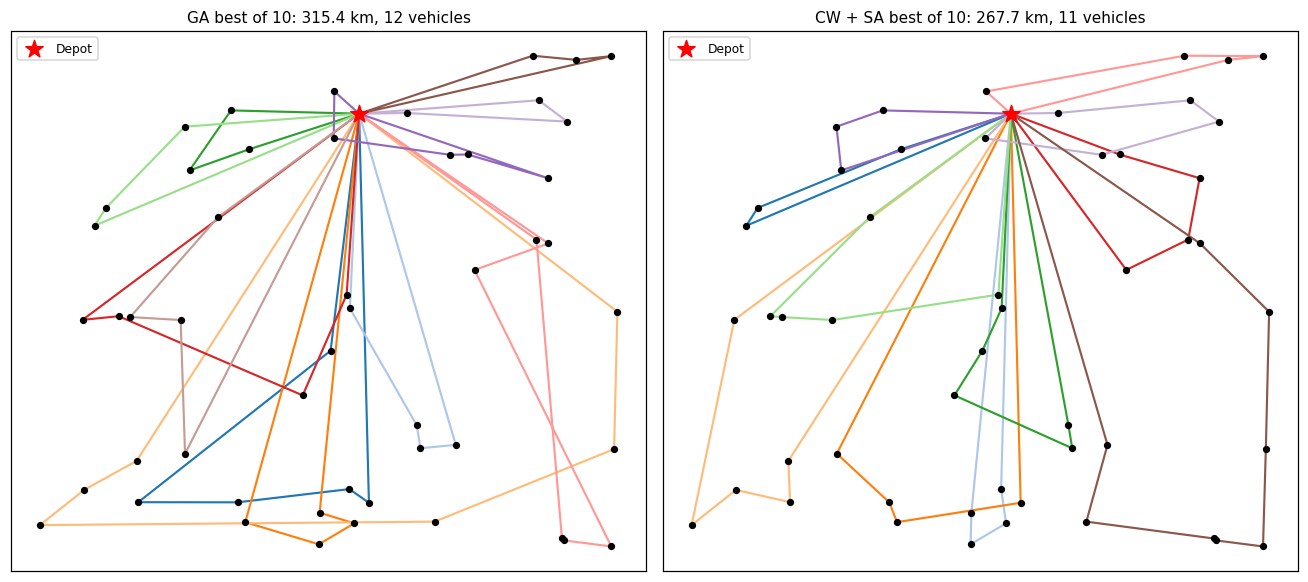

In [18]:
def plot_routes(ax, I, routes, title):
    pts = np.array(I["pts"])
    cmap = plt.get_cmap("tab20")
    for k, r in enumerate(routes):
        seq = [0] + r + [0]
        ax.plot(pts[seq, 1], pts[seq, 0], "-", color=cmap(k % 20), lw=1.4)
    ax.scatter(pts[1:, 1], pts[1:, 0], s=14, c="k", zorder=3)
    ax.scatter(pts[0, 1], pts[0, 0], s=140, marker="*", c="red", zorder=4, label="Depot")
    ax.set_title(title, fontsize=10); ax.set_xticks([]); ax.set_yticks([]); ax.legend(fontsize=8)

n = 50
best_ga = min((r for r in records if r["n"] == n and r["method"] == "GA (Member 1)"), key=lambda r: r["distance"])
best_sa = min((r for r in records if r["n"] == n and r["method"] == "CW + SA (Member 2)"), key=lambda r: r["distance"])
fig, ax = plt.subplots(1, 2, figsize=(12, 5.4))
plot_routes(ax[0], INSTANCES[n], best_ga["routes"], f"GA best of 10: {best_ga['distance']:.1f} km, {best_ga['vehicles']} vehicles")
plot_routes(ax[1], INSTANCES[n], best_sa["routes"], f"CW + SA best of 10: {best_sa['distance']:.1f} km, {best_sa['vehicles']} vehicles")
plt.tight_layout(); plt.savefig(OUT_DIR / "routes_n50.png", dpi=150); plt.show()

## 8. Key findings (numbers are filled in automatically)

In [19]:
def row(n, m):
    return summary[(summary.n == n) & (summary.method == m)].iloc[0]

o, c = ilp15_orig, ilp15_cut
print("1. Original 15-customer ILP claim")
print(f"   Original model : {o['distance']:.2f} km, LB {o['lower_bound']:.2f}, {o['time_s']:.0f} s -> {o['status']}")
print(f"   With fleet cut : {c['distance']:.2f} km, LB {c['lower_bound']:.2f}, {c['time_s']:.0f} s -> {c['status']}")

proven = ilp_table[ilp_table["status"].str.startswith("Optimal")]["n"].tolist()
print(f"\n2. ILP proves optimality for n in {proven}; larger instances stop on the {ILP_TIME_LIMIT} s limit.")
for _, r in ilp_table.iterrows():
    print(f"   n={int(r.n):>3}: {r.status:<22} MIP gap {r['mip_gap_%']:.2f}%  time {r.time_s:.1f} s")

print("\n3. Heuristic quality (mean over 10 seeds, gap to best known)")
for n in SIZES:
    g, s, w = row(n, "GA (Member 1)"), row(n, "CW + SA (Member 2)"), row(n, "Clarke-Wright")
    print(f"   n={n:>3}: CW {w['gap_best_known_%']:5.2f}% | GA {g['gap_best_known_%']:5.2f}% (±{g['std']:.2f} km, {g.time_mean_s:.1f}s)"
          f" | CW+SA {s['gap_best_known_%']:5.2f}% (±{s['std']:.2f} km, {s.time_mean_s:.1f}s)")

1. Original 15-customer ILP claim
   Original model : 106.47 km, LB 76.52, 300 s -> Feasible, time limit
   With fleet cut : 104.22 km, LB 104.22, 176 s -> Optimal (proven)

2. ILP proves optimality for n in [8, 10, 12, 15]; larger instances stop on the 300 s limit.
   n=  8: Optimal (proven)       MIP gap 0.00%  time 0.6 s
   n= 10: Optimal (proven)       MIP gap 0.00%  time 1.0 s
   n= 12: Optimal (proven)       MIP gap 0.00%  time 3.1 s
   n= 15: Optimal (proven)       MIP gap 0.00%  time 176.0 s
   n= 20: Feasible, time limit   MIP gap 29.46%  time 300.1 s
   n= 30: Feasible, time limit   MIP gap 52.36%  time 299.3 s

3. Heuristic quality (mean over 10 seeds, gap to best known)
   n=  8: CW  0.00% | GA  0.79% (±1.10 km, 1.6s) | CW+SA  0.00% (±0.00 km, 0.3s)
   n= 10: CW  5.02% | GA  0.37% (±0.47 km, 1.8s) | CW+SA  0.00% (±0.00 km, 0.3s)
   n= 12: CW  0.73% | GA  0.71% (±0.79 km, 1.9s) | CW+SA  0.00% (±0.00 km, 0.3s)
   n= 15: CW  3.67% | GA  4.43% (±2.30 km, 2.0s) | CW+SA  1.72% (±

## 9. Discussion

* **Exact method.** The MTZ formulation is compact but its LP relaxation is weak (big-$Q$ constraints), so CBC needs exponential branching. The run-time wall appears quickly, which is the practical face of NP-hardness. Reporting `sol_status` and the lower bound turns "the solver said Optimal" into a verifiable statement. Where the ILP cannot finish, its lower bound is still valuable: it certifies how far any heuristic can be from optimal.
* **Construction vs improvement.** Clarke-Wright alone is near-instant and already competitive, which is why it is still widely used in industry. Adding SA on top recovers most of the remaining gap at a small, predictable cost.
* **Trajectory vs population search.** The GA's giant-tour split cuts the permutation strictly in order, so a good customer sequence can still produce badly filled vehicles. Its fitness budget (100,000 evaluations) is fixed regardless of $n$, so its quality degrades as $n$ grows. SA's moves work on the routes directly and respect capacity, and its iteration budget scales with $n$.
* **No real elitism in the GA.** Because `eaSimple` never re-inserts the Hall of Fame, the population's best tour drifts up and down (convergence plot), and at large $n$ the GA spends much of its budget re-finding solutions it already had. This, plus the fixed budget and the in-order split, explains its widening gap and its high variance at $n = 50$ and $100$.
* **Robustness.** Standard deviations across seeds show how much a single run can be trusted. A method with a low mean but high variance is risky for daily dispatch.

### Limitations
* Coordinates are synthetic (deterministic pseudo-geocoding), and distances are straight-line haversine rather than road network distances.
* Demand is proxied by order value (`total_amount / 100`), not physical size or weight.
* A single depot and a static order set are assumed (no time windows, no dynamic arrivals).

### Future work
* A stronger exact model (rounded capacity cuts or branch-and-cut-and-price, e.g. VRPSolver), or OR-Tools CP-SAT.
* Road-network distances from OpenStreetMap (OSMnx) and real travel times.
* Time windows (VRPTW) for food freshness, multi-depot routing, and rolling-horizon re-optimisation as orders arrive.
* A hybrid memetic algorithm: GA with SA or local search applied to offspring, and an optimal split (Prins, 2004) instead of the greedy split.